# 10 · SVM pro diagnostiku čerpadel

Praktická část cvičení 10. Na provozních záznamech odstředivých čerpadel porovnáte lineární model se SVM s jádry,
**samostatně vyladíte C a γ** křížovou validací, zvolíte rozhodovací práh podle ceny chyb a výsledek jednou otestujete.
Potom vyzkoušíte dvě další úlohy SVM z přednášky: jednotřídní SVM naučenou bez označených poruch a regresi charakteristiky
čerpadla s ε-trubicí včetně extrapolace. Každé nastavení, které zde ladíte, jste viděli v edukační části `svm-visual-cz.ipynb`.

Krátké spustitelné ukázky používají malá ilustrační data a proměnné s předponou `demo_`. Spouštějte je v pořadí;
ukazují syntaxi celého postupu. Vlastní řešení pište do prázdných kódových buněk pod úkoly.
Testovací data se otevřou až v kroku 7. Po dokončení spusťte `Restart Kernel and Run All` a ověřte, že řešení běží v pořadí.

## Příprava prostředí a načtení dat

1. Otevřete notebook v Jupyteru (balíčky popisuje README) nebo v Google Colab.
2. Spusťte ukázku níže. Importuje všechny potřebné nástroje a připraví malá ilustrační data `demo_`.
3. Připravená buňka pod ní načte data do tabulky `raw` a nastaví `SEED = 42`. Když notebook běží ve složce cvičení
   nebo v kořeni repozitáře, použije místní soubor `data/pumps.csv`; jinak vytvoří stejnou tabulku stejným generátorem
   (kód `prepare_data.py`), takže není potřeba nic stahovat.

### Ukázka: importy a ilustrační data

In [1]:
from IPython.display import display                          # Zobrazení tabulek.
import matplotlib.pyplot as plt                              # Grafy.
import numpy as np                                           # Numerické výpočty.
import pandas as pd                                          # Data a tabulky výsledků.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV  # Dělení, křížová validace a mřížkové hledání.
from sklearn.pipeline import Pipeline                        # Řetězení škálování a modelu.
from sklearn.preprocessing import StandardScaler             # Standardizace.
from sklearn.linear_model import LogisticRegression          # Logistický neuron z přednášky 09.
from sklearn.svm import SVC, SVR, OneClassSVM                # SVM pro klasifikaci, regresi a jednu třídu.
from sklearn.metrics import confusion_matrix, roc_auc_score, mean_absolute_error  # Matice záměn, ROC AUC, MAE.

demo_rng = np.random.default_rng(7)                          # Ilustrační data, ne data úlohy.
demo_X = pd.DataFrame({"a": demo_rng.normal(0, 1, 400), "b": demo_rng.normal(0, 10, 400)})  # Dva příznaky v různých měřítkách.
demo_y = ((demo_X["a"] ** 2 + (demo_X["b"] / 10) ** 2) > 1.6).astype(int)  # Třída 1 vně kružnice: žádná přímka ji neoddělí.
demo_X_dev, demo_X_test, demo_y_dev, demo_y_test = train_test_split(demo_X, demo_y, test_size=0.25, stratify=demo_y, random_state=7)  # Čtvrtina pro test.
demo_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)  # Pět částí se stejným podílem tříd.
print(len(demo_X_dev), len(demo_X_test), "podíl třídy 1:", round(demo_y.mean(), 3))  # Velikosti a podíl.

300 100 podíl třídy 1: 0.412


**Připravený kód:**

In [2]:
from pathlib import Path                                     # Cesty k místní kopii dat.
SEED = 42                                                    # Stejné náhodné dělení pro všechny.


def make_pumps(seed=20261124, n=900):
    # Generátor z prepare_data.py: stejná tabulka bez stahování.
    rng = np.random.default_rng(seed)
    flow = rng.uniform(20, 80, n)
    deviation = rng.normal(0, 0.45, n)
    pressure = 6.0 - 0.0006 * flow ** 2 + deviation
    bearing_temp = rng.normal(60, 6, n)
    current = 18 + 0.12 * flow + 0.4 * pressure + rng.normal(0, 0.6, n)
    vibration = np.exp(rng.normal(-0.5, 0.35, n))
    ambient_temp = rng.normal(22, 4, n)
    risk = (deviation / 0.45) ** 2 + ((bearing_temp - 60) / 6) ** 2 + rng.normal(0, 0.6, n)
    return pd.DataFrame({"record_id": [f"R{i:03d}" for i in range(1, n + 1)], "flow": flow.round(1), "pressure": pressure.round(3),
                         "bearing_temp": bearing_temp.round(1), "current": current.round(2), "vibration": vibration.round(3),
                         "ambient_temp": ambient_temp.round(1), "fault": (risk > 3.2).astype(int)})


local = [Path("data/pumps.csv"), Path("10-SVM/data/pumps.csv")]  # Složka cvičení nebo kořen repozitáře.
found = [path for path in local if path.exists()]           # Místní kopie, které existují.
raw = pd.read_csv(found[0]) if found else make_pumps()       # Bez místní kopie (např. Google Colab) vytvořit stejná data.
print("zdroj dat:", found[0] if found else "make_pumps()")  # Soubor nebo generátor.
display(raw.head())                                          # Prvních pět řádků.

zdroj dat: data\pumps.csv


,record_id,flow,pressure,bearing_temp,current,vibration,ambient_temp,fault
0,R001,77.6,2.490,62.5,28.01,0.888,17.7,0
1,R002,77.8,1.723,66.2,27.78,0.736,19.2,0
2,R003,27.5,6.634,49.1,23.00,0.974,23.7,1
3,R004,40.6,4.673,62.4,23.82,0.678,18.6,0
4,R005,54.5,4.243,65.4,26.82,1.279,24.5,0


## Úloha a data

Každý řádek je jeden **provozní záznam odstředivého čerpadla** (všechna čerpadla jsou stejného typu) s výsledkem prohlídky `fault`
(1 = nalezena porucha). Data jsou syntetická; jejich popis je v `data/README.md`.

| Sloupec | Význam | Typická hodnota |
|---|---|---|
| `flow` | průtok, pracovní bod | 20 až 80 m³/h |
| `pressure` | výtlačný tlak | 2 až 6 bar |
| `bearing_temp` | teplota ložiska | 60 °C |
| `current` | proud motoru | 28 A |
| `vibration` | rychlost vibrací | 0,6 mm/s |
| `ambient_temp` | teplota okolí | 22 °C |

**Cíl:** označit záznamy, u kterých se má provést prohlídka. **Ceny:** přehlédnutá porucha (FN) stojí **10** jednotek (neplánovaná odstávka),
zbytečná prohlídka (FP) stojí **1** jednotku. Kvalita rozhodnutí se měří **celkovými náklady** 10·FN + 1·FP.
(Náklady se zde neoznačují C, aby se nepletly s parametrem C metody SVM.)

## 1. Prohlídka dat (připraveno)

**Výstup:** podíl poruch, tabulka rozsahů příznaků a dva bodové grafy. Všimněte si, kde leží poruchy vzhledem
k mraku běžných záznamů v grafu průtoku a tlaku.

**Připravený kód:**

řádků: 900 | podíl poruch: 0.19


,mean,std,min,max
flow,50.22,17.45,20.10,80.00
pressure,4.30,1.15,1.24,6.98
bearing_temp,60.14,5.96,41.30,78.70
current,25.69,1.78,21.71,29.58
vibration,0.64,0.23,0.16,1.82
ambient_temp,21.96,3.94,8.00,33.60


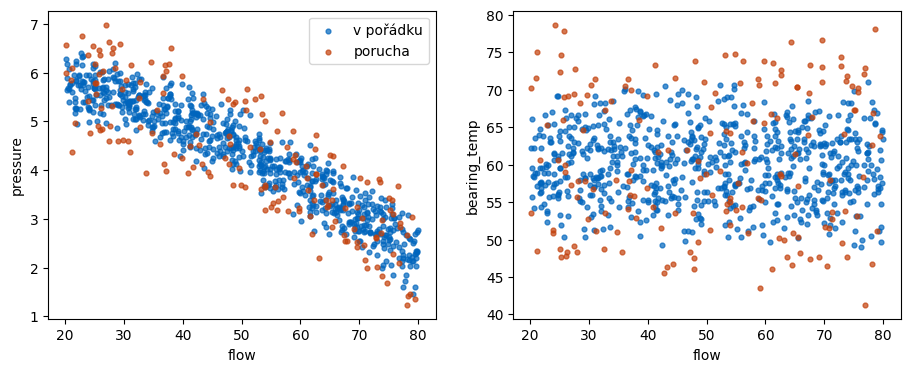

In [3]:
print("řádků:", len(raw), "| podíl poruch:", round(raw["fault"].mean(), 3))  # Velikost a podíl tříd.
display(raw.drop(columns=["record_id", "fault"]).describe().T[["mean", "std", "min", "max"]].round(2))  # Rozsahy vstupů.
fig, axs = plt.subplots(1, 2, figsize=(11, 4))               # Dva grafy vedle sebe.
for ax, col in zip(axs, ["pressure", "bearing_temp"]):       # Tlak a teplota ložiska proti průtoku.
    for value, colour, label in ((0, "#0065BD", "v pořádku"), (1, "#C2410C", "porucha")):
        part = raw[raw["fault"] == value]
        ax.scatter(part["flow"], part[col], s=12, color=colour, label=label, alpha=0.7)
    ax.set(xlabel="flow", ylabel=col)
axs[0].legend()
plt.show()                                                   # Zobrazit grafy.

## 2. Příznaky a pevné rozdělení (připraveno)

**Výstup:** `X` (šest vstupů) a `y` (`fault`); vývojová část `X_dev`, `y_dev` (675 záznamů) a testovací část `X_test`, `y_test`
(225 záznamů), která zůstává zavřená až do kroku 7; rozdělení `CV` (pětinásobná stratifikovaná křížová validace) pro všechna srovnání.

**Připravený kód:**

In [4]:
FEATURES = ["flow", "pressure", "bearing_temp", "current", "vibration", "ambient_temp"]  # Šest vstupů.
X = raw[FEATURES]                                            # Vstupy; record_id není vstup.
y = raw["fault"]                                             # Cílová třída.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)  # Čtvrtina pro test, stratifikovaně.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # Stejných pět částí pro každý model.
print(f"dev {len(y_dev)} záznamů, {int(y_dev.sum())} poruch | test {len(y_test)} záznamů, {int(y_test.sum())} poruch")

dev 675 záznamů, 128 poruch | test 225 záznamů, 43 poruch


## 3. Funkce pro vyhodnocení a referenční model (připraveno)

**Výstup:** `cv_auc(model)` vrací průměrné ROC AUC pětinásobné křížové validace na vývojových datech
(ROC AUC nezávisí na prahu, proto se používá pro ladění); `evaluate(y_true, y_pred)` vrací počty z matice záměn,
přesnost, úplnost a celkové náklady. Referencí je logistický neuron ze cvičení 09 se škálováním.

**Připravený kód:**

In [5]:
def cv_auc(model, X_=None, y_=None, cv=None):
    # Průměrné ROC AUC přes části; výchozí jsou vývojová data a CV.
    X_ = X_dev if X_ is None else X_
    y_ = y_dev if y_ is None else y_
    return cross_val_score(model, X_, y_, cv=CV if cv is None else cv, scoring="roc_auc").mean()


def evaluate(y_true, y_pred):
    # Počty, dvě metriky a náklady 10·FN + 1·FP.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "přesnost": tp / max(tp + fp, 1),
            "úplnost": tp / max(tp + fn, 1), "náklady": 10 * fn + fp}


reference = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression())])  # Škálování, potom logistický neuron.
print("logistický neuron, CV ROC AUC:", round(cv_auc(reference), 3))  # Kolem 0,5 = ne lépe než náhoda.
print("náklady „vše v pořádku“ na dev:", 10 * int(y_dev.sum()))  # Každá porucha přehlédnuta.

logistický neuron, CV ROC AUC: 0.457
náklady „vše v pořádku“ na dev: 1280


## 4. Lineární model a jádra

**Cíl / výstup:** tabulka `kernel_results` s CV ROC AUC čtyř modelů na vývojových datech:

1. lineární SVM: `Pipeline` s kroky `scale`: `StandardScaler()` → `model`: `SVC(kernel="linear")`;
2. polynomiální jádro stupně 2: `SVC(kernel="poly", degree=2, coef0=1)` po škálování;
3. RBF jádro s výchozím nastavením: `SVC()` po škálování;
4. stejné RBF jádro **bez** škálování.

**Použijte:** `Pipeline`, `StandardScaler`, `SVC`, `cv_auc`, `pd.Series` nebo `pd.DataFrame`.

<details><summary>Nápověda</summary>

Jádro se zadává argumentem `kernel` (`"linear"`, `"poly"`, `"rbf"`; výchozí je `"rbf"` s `C=1` a `gamma="scale"`).
`coef0=1` přidá do polynomiálního jádra (γ·x·z + 1)^d konstantu r = 1, takže obsahuje všechny součiny až do stupně d.
Výsledky sbírejte do slovníku `{název: cv_auc(model)}` a převeďte na `pd.Series(...)`.

</details>

**Zamyslete se:** Proč není lineární model lepší než náhoda (podívejte se na graf v kroku 1)? Proč už pomůže stupeň 2?
Jak moc záleží na škálování a proč (edukační část, oddíl 5)?

### Ukázka: jádra na ilustračních datech

In [6]:
demo_models = {                                              # Tři jádra po škálování, jedno bez něj.
    "lineární": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="linear"))]),
    "poly 2": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="poly", degree=2, coef0=1))]),
    "RBF": Pipeline([("scale", StandardScaler()), ("model", SVC())]),
    "RBF bez škálování": SVC(),
}
demo_results = pd.Series({name: cv_auc(model, demo_X_dev, demo_y_dev, demo_cv) for name, model in demo_models.items()}, name="CV ROC AUC")  # Jedno číslo na model.
display(demo_results.round(3))                               # Kružnice potřebuje jádro a škálování.

lineární             0.609
poly 2               0.998
RBF                  0.997
RBF bez škálování    0.850
Name: CV ROC AUC, dtype: float64

**Vlastní kód:**

In [7]:
models = {
    "lineární SVM": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="linear"))]),
    "polynomiální d = 2": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="poly", degree=2, coef0=1))]),
    "RBF": Pipeline([("scale", StandardScaler()), ("model", SVC())]),
    "RBF bez škálování": SVC(),
}
kernel_results = pd.Series({name: cv_auc(model) for name, model in models.items()}, name="CV ROC AUC")
display(kernel_results.round(3))

lineární SVM          0.493
polynomiální d = 2    0.858
RBF                   0.867
RBF bez škálování     0.796
Name: CV ROC AUC, dtype: float64

**Poznámky k řešení (krok 4).** CV ROC AUC: lineární SVM 0,49, polynomiální stupně 2 0,86, RBF 0,87, RBF bez škálování 0,80
(logistický neuron v kroku 3: 0,46). Porucha je odchylka od charakteristiky čerpadla **na kteroukoli stranu** a neobvyklá teplota
ložiska oběma směry; taková třída leží kolem běžných záznamů, ne na jedné jejich straně, a žádná nadrovina ji neoddělí.
Stupeň 2 přidá čtverce a součiny příznaků, což na zakřivený pás stačí. Bez škálování převáží ve vzdálenostech
RBF jádra průtok (desítky).

## 5. Ladění C a γ

**Cíl / výstup:** naučený objekt `GridSearchCV` `grid` pro RBF pipeline, teplotní mapa jeho CV ROC AUC a výsledný
`best_svm` (jeho `best_estimator_`) s počtem podpůrných vektorů.

1. Pipeline `scale` → `model`: `SVC()`; mřížka `model__C` ∈ {0,1; 1; 10; 100}, `model__gamma` ∈ {0,01; 0,1; 1; 10};
   `cv=CV`, `scoring="roc_auc"`. Naučte ji na vývojových datech.
2. Zobrazte průměrné CV skóre jako tabulku C × γ (`pivot_table`) a jako teplotní mapu.
3. Pokud nejlepší hodnota leží **na kraji mřížky**, rozšiřte mřížku tím směrem (a kolem nejlepšího γ) a hledejte znovu.
   Opakujte, dokud se nejlepší CV skóre znatelně zlepšuje (o víc než asi 0,005). Výsledné hledání uložte do `grid`
   a jeho nejlepší model do `best_svm`.
4. Vypište počet podpůrných vektorů `best_svm` (`best_svm[-1].n_support_`) vzhledem k počtu učebních záznamů.

**Použijte:** `GridSearchCV`, `.cv_results_`, `pd.DataFrame(...).pivot_table(...)`, `plt.imshow`, `.best_params_`, `.best_score_`, `.best_estimator_`.

<details><summary>Nápověda</summary>

Parametry kroku pipeline se jmenují `krok__parametr`, zde `model__C` a `model__gamma`. Tabulka:
`pd.DataFrame(grid.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")`.
`GridSearchCV` nejlepší kombinaci znovu naučí na všech vývojových datech (výchozí `refit=True`).

</details>

**Zamyslete se:** Kterým směrem jste mřížku rozšířili? Změnilo se C i γ? Jak nejlepší model souvisí se snímkem přednášky
o společné volbě C a γ?

### Ukázka: mřížkové hledání na ilustračních datech

param_model__gamma,0.1,1.0,10.0
param_model__C,,,
0.1,0.958,0.997,0.993
1.0,1.000,0.997,0.991
10.0,0.998,0.999,0.987


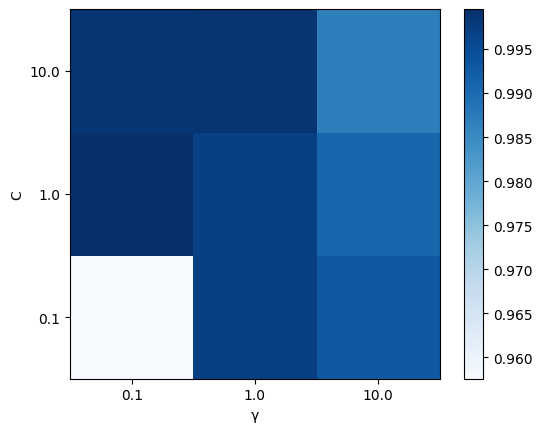

{'model__C': 1, 'model__gamma': 0.1} 1.0 podpůrné vektory: 131


In [8]:
demo_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])  # Škálování a RBF SVM.
demo_grid = GridSearchCV(demo_pipe, {"model__C": [0.1, 1, 10], "model__gamma": [0.1, 1, 10]},  # Devět kombinací.
                         cv=demo_cv, scoring="roc_auc").fit(demo_X_dev, demo_y_dev)  # Každá s křížovou validací.
demo_table = pd.DataFrame(demo_grid.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")  # Tabulka C × γ.
display(demo_table.round(3))
plt.imshow(demo_table.values, cmap="Blues", origin="lower")  # Teplotní mapa; řádky C, sloupce γ.
plt.xticks(range(3), demo_table.columns); plt.yticks(range(3), demo_table.index)
plt.xlabel("γ"); plt.ylabel("C"); plt.colorbar(); plt.show()
print(demo_grid.best_params_, round(demo_grid.best_score_, 3), "podpůrné vektory:", demo_grid.best_estimator_[-1].n_support_.sum())

**Vlastní kód:**

param_model__gamma,0.01,0.10,1.00,10.00
param_model__C,,,,
0.1,0.824,0.843,0.854,0.777
1.0,0.824,0.854,0.850,0.777
10.0,0.826,0.898,0.830,0.777
100.0,0.861,0.908,0.829,0.777


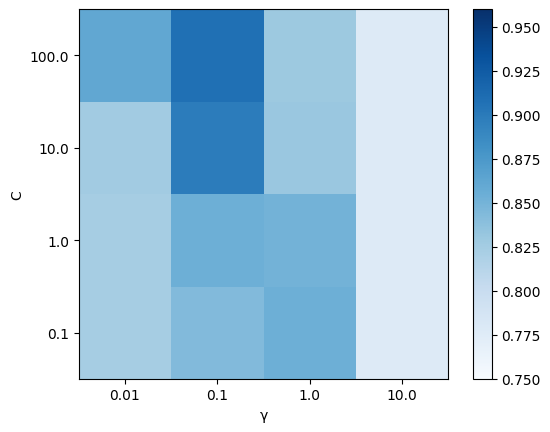

{'model__C': 100, 'model__gamma': 0.1} 0.908


param_model__gamma,0.001,0.003,0.010,0.030,0.100
param_model__C,,,,,
100,0.819,0.824,0.861,0.908,0.908
1000,0.826,0.858,0.915,0.938,0.858
10000,0.861,0.919,0.944,0.906,0.846
100000,0.916,0.950,0.933,0.859,0.846


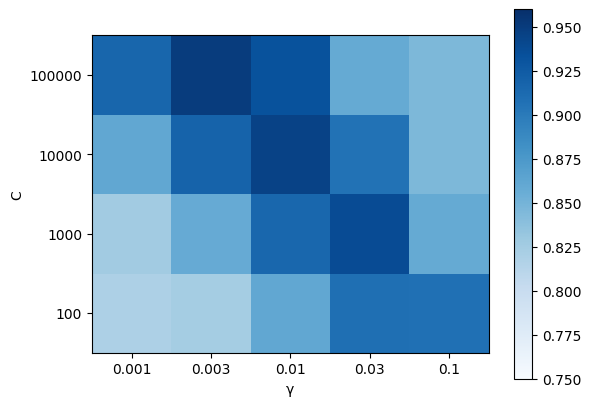

{'model__C': 100000, 'model__gamma': 0.003} 0.95


C = 10⁶: nejlepší CV ROC AUC 0.951 – plató, dál se nerozšiřuje
podpůrné vektory po třídách: [75 66] z 675


In [9]:
pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])


def show_grid(search):
    table = pd.DataFrame(search.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")
    display(table.round(3))
    plt.imshow(table.values, cmap="Blues", origin="lower", vmin=0.75, vmax=0.96)
    plt.xticks(range(table.shape[1]), table.columns); plt.yticks(range(table.shape[0]), table.index)
    plt.xlabel("γ"); plt.ylabel("C"); plt.colorbar(); plt.show()
    print(search.best_params_, round(search.best_score_, 3))


first = GridSearchCV(pipe, {"model__C": [0.1, 1, 10, 100], "model__gamma": [0.01, 0.1, 1, 10]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
show_grid(first)
# Nejlepší C = 100 je na kraji: rozšířit C nahoru a γ dolů (dobré buňky leží na úhlopříčce).
grid = GridSearchCV(pipe, {"model__C": [100, 1000, 10000, 100000], "model__gamma": [0.001, 0.003, 0.01, 0.03, 0.1]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
show_grid(grid)
# C = 100000 je opět na kraji: ještě jedna kontrola dál po úhlopříčce.
further = GridSearchCV(pipe, {"model__C": [1000000], "model__gamma": [0.001, 0.003]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
print("C = 10⁶: nejlepší CV ROC AUC", round(further.best_score_, 3), "– plató, dál se nerozšiřuje")
best_svm = grid.best_estimator_
print("podpůrné vektory po třídách:", best_svm[-1].n_support_, "z", len(X_dev))

**Poznámky k řešení (krok 5).** První mřížka má nejlepší CV ROC AUC 0,908 pro C = 100, γ = 0,1 – na kraji C. Dobré buňky leží na úhlopříčce
(větší C s menším γ), proto druhá mřížka rozšiřuje C nahoru a γ dolů: 0,938 pro C = 1000, γ = 0,03, 0,944 pro C = 10⁴, γ = 0,01 a
**0,950 pro C = 10⁵, γ = 0,003** – opět na kraji. C = 10⁶ dá 0,950–0,951: plató, hledání končí. Po této úhlopříčce je hranice
RBF hladká (malé γ) a přísná (velké C); blíží se polynomu nízkého stupně, který odpovídá skutečnému tvaru tříd
(vyladěné polynomiální jádro stupně 2 dosáhne asi 0,94). Nejlepší model má 141 podpůrných vektorů (75 + 66) ze 675 záznamů.
Učení s C = 10⁵ je znatelně pomalejší než s C = 1.

## 6. Práh podle ceny chyb

**Cíl / výstup:** skóre `dev_scores` nejlepšího nastavení z křížové validace na vývojových datech, graf celkových nákladů
v závislosti na prahu, práh `best_threshold` s nejnižšími náklady a srovnání s prahem 0 (výchozí práh `predict`).

1. `dev_scores = cross_val_predict(best_svm, X_dev, y_dev, cv=CV, method="decision_function")` – každý záznam dostane skóre od modelu,
   který ho neviděl.
2. Pro prahy od −2 do 1 (krok 0,05) spočtěte náklady `(dev_scores >= práh)`; vykreslete je a najděte minimum.
3. Vypište `evaluate` pro nejlepší práh a pro 0.

**Použijte:** `cross_val_predict`, `np.arange`, `evaluate`, `plt.plot`.

<details><summary>Nápověda</summary>

Skóre SVM je hodnota w·φ(x) + b podobná vzdálenosti, ne pravděpodobnost; `predict` používá práh 0. Záporný práh
označí za poruchu více záznamů: méně FN, více FP. Při poměru cen 10 : 1 bývá nejlepší práh pod nulou.

</details>

**Zamyslete se:** Kolik přehlédnutých poruch a kolik zbytečných prohlídek dávají oba prahy? Proč se práh volí na vývojových
datech, a ne na testovacích?

**Vlastní kód:**

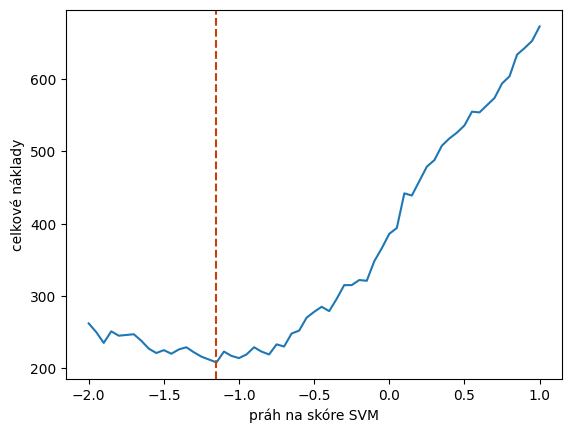

,TN,FP,FN,TP,přesnost,úplnost,náklady
práh -1.15,449,98,11,117,0.544,0.914,208
práh 0,531,16,37,91,0.850,0.711,386


In [10]:
dev_scores = cross_val_predict(best_svm, X_dev, y_dev, cv=CV, method="decision_function")
thresholds = np.round(np.arange(-2, 1.0001, 0.05), 2)
costs = [evaluate(y_dev, (dev_scores >= t).astype(int))["náklady"] for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="#C2410C", ls="--")
plt.xlabel("práh na skóre SVM"); plt.ylabel("celkové náklady"); plt.show()
display(pd.DataFrame([evaluate(y_dev, (dev_scores >= best_threshold).astype(int)), evaluate(y_dev, (dev_scores >= 0).astype(int))],
                     index=[f"práh {best_threshold}", "práh 0"]).round(3))

**Poznámky k řešení (krok 6).** Nejnižší náklady na vývojových datech jsou **208 při prahu −1,15** (TN 449, FP 98, FN 11, TP 117; úplnost 0,91),
oproti 386 při prahu 0 (FN 37, FP 16; úplnost 0,71) a 1280 pro „vše v pořádku“. Křivka nákladů je u minima plochá,
sousední prahy dávají podobné náklady. Volba prahu na testovacích datech by výsledek testu nadsadila: test by už nebyl
nezávislou kontrolou.

## 7. Závěrečný test (jednou)

**Cíl / výstup:** `test_scores` = `best_svm.decision_function(X_test)`, ROC AUC na testovacích datech a tabulka `test_result`
s `evaluate` pro `best_threshold` a pro 0 a náklady „vše v pořádku“ na testovacích datech. Nic se už neladí.

**Vlastní kód:**

In [11]:
test_scores = best_svm.decision_function(X_test)
print("ROC AUC na testu:", round(roc_auc_score(y_test, test_scores), 3))
test_result = pd.DataFrame([evaluate(y_test, (test_scores >= best_threshold).astype(int)), evaluate(y_test, (test_scores >= 0).astype(int))],
                           index=[f"práh {best_threshold}", "práh 0"])
display(test_result.round(3))
print("náklady „vše v pořádku“:", 10 * int(y_test.sum()))

ROC AUC na testu: 0.952


,TN,FP,FN,TP,přesnost,úplnost,náklady
práh -1.15,156,26,5,38,0.594,0.884,76
práh 0,178,4,16,27,0.871,0.628,164


náklady „vše v pořádku“: 430


**Poznámky k řešení (krok 7).** ROC AUC na testu 0,952, blízko hodnotě 0,950 z křížové validace. Při prahu −1,15 jsou náklady **76**
(FN 5, FP 26, úplnost 0,88), při prahu 0 jsou 164 (FN 16, FP 4) a „vše v pořádku“ stojí 430.

## 8. Jednotřídní SVM bez označených poruch (rozšiřující)

Kroky 8 a 9 jsou rozšiřující: v hodině, pokud zbude čas, jinak doma.

V praxi často chybí označené poruchy; jsou jen záznamy běžného provozu. **Cíl / výstup:** tabulka `oc_results`
s validačním ROC AUC jednotřídní SVM pro ν ∈ {0,02; 0,05; 0,1} a γ ∈ {0,03; 0,1; 0,3; 1}, zvolené nastavení
a ROC AUC výsledného jednotřídního modelu `oc_model` na testu.

1. Rozdělte vývojová data ještě jednou: `X_oc_train, X_oc_val, y_oc_train, y_oc_val` (30 % validace, stratifikovaně, `SEED`).
2. Pro každou kombinaci naučte `Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=..., gamma=...))])`
   **jen na záznamech v pořádku** `X_oc_train[y_oc_train == 0]`; ROC AUC vyhodnoťte na `X_oc_val` se skóre
   `-model.decision_function(...)` (vyšší = neobvyklejší).
3. Nejlepší kombinaci naučte znovu na všech záznamech v pořádku z vývojových dat; vypište ROC AUC na testu, podíl testovacích záznamů
   v pořádku označených jako odchylka a podíl nalezených testovacích poruch (`predict == -1`).

**Použijte:** `train_test_split`, `OneClassSVM`, `roc_auc_score`, `.decision_function`, `.predict`.

<details><summary>Nápověda</summary>

Označení validační části se používá jen k **vyhodnocení** nastavení, nikdy k učení modelu. `decision_function` jednotřídní
SVM je uvnitř hranice kladné, jeho záporná hodnota je tedy skóre odchylky.

</details>

**Zamyslete se:** Jak daleko je jednotřídní model od SVM s učitelem z kroku 7? Kdy byste ho přesto použili?

**Vlastní kód:**

In [12]:
X_oc_train, X_oc_val, y_oc_train, y_oc_val = train_test_split(X_dev, y_dev, test_size=0.3, stratify=y_dev, random_state=SEED)
rows = []
for nu in (0.02, 0.05, 0.1):
    for gamma in (0.03, 0.1, 0.3, 1):
        model = Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=nu, gamma=gamma))]).fit(X_oc_train[y_oc_train == 0])
        rows.append({"nu": nu, "gamma": gamma, "validační ROC AUC": roc_auc_score(y_oc_val, -model.decision_function(X_oc_val))})
oc_results = pd.DataFrame(rows)
display(oc_results.pivot_table(index="nu", columns="gamma", values="validační ROC AUC").round(3))
best = oc_results.iloc[oc_results.iloc[:, 2].idxmax()]
oc_model = Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=best["nu"], gamma=best["gamma"]))]).fit(X_dev[y_dev == 0])
print("zvoleno ν =", best["nu"], "γ =", best["gamma"])
print("ROC AUC na testu:", round(roc_auc_score(y_test, -oc_model.decision_function(X_test)), 3))
print("záznamy v pořádku označené:", round((oc_model.predict(X_test[y_test == 0]) == -1).mean(), 3),
      "| nalezené poruchy:", round((oc_model.predict(X_test[y_test == 1]) == -1).mean(), 3))

gamma,0.03,0.10,0.30,1.00
nu,,,,
0.02,0.719,0.766,0.821,0.800
0.05,0.718,0.759,0.821,0.801
0.10,0.714,0.763,0.823,0.801


zvoleno ν = 0.1 γ = 0.3
ROC AUC na testu: 0.854
záznamy v pořádku označené: 0.137 | nalezené poruchy: 0.721


**Poznámky k řešení (krok 8).** Validační ROC AUC je 0,71–0,82; γ rozhoduje mnohem víc než ν. Nejlepší je ν = 0,1, γ = 0,3 (0,823).
Na testu dosáhne jednotřídní model ROC AUC **0,854** bez jediné označené poruchy, oproti 0,952 pro SVM s učitelem.
Označí 14 % testovacích záznamů v pořádku a najde 72 % poruch. Hodí se, když poruchy v datech chybějí
nebo jsou nové a jiné než známé; model s učitelem je lepší, když je označených poruch dost.

## 9. Charakteristika čerpadla: regrese s ε-trubicí a extrapolace (rozšiřující)

**Cíl / výstup:** tabulka `svr_results` s MAE tří modelů SVR uvnitř a vně učebního rozsahu, graf tří
křivek a tabulka `eps_results` s počtem podpůrných vektorů a MAE pro ε ∈ {0,05; 0,2; 0,5}.

1. Vezměte vývojové záznamy **v pořádku** (`y_dev == 0`). Vstup: jen `flow`, cíl: `pressure`.
   Učební rozsah: průtok < 65 m³/h; „nový rozsah“: průtok ≥ 65 (tam čerpadlo v učebních datech nikdy nepracovalo).
2. Naučte tři pipeline (škálování → `SVR`) s `C=10, epsilon=0.2`: lineární jádro, polynomiální `degree=2, coef0=1`, RBF `gamma=1`.
   Vypište MAE v učebním rozsahu a v novém rozsahu.
3. Vykreslete data a tři křivky pro průtok od 20 do 80.
4. U polynomiálního jádra měňte ε na 0,05; 0,2 a 0,5; vypište počet podpůrných vektorů a obě hodnoty MAE.

**Použijte:** `SVR`, `mean_absolute_error`, `.support_`, `plt.plot`.

<details><summary>Nápověda</summary>

`SVR` potřebuje dvourozměrný vstup: `data[["flow"]]`, ne `data["flow"]`. Šum tlaku kolem charakteristiky má směrodatnou
odchylku asi 0,45 bar, takže MAE kolem 0,27 je to nejlepší, čeho může uvnitř dat dosáhnout jakýkoli model.

</details>

**Zamyslete se:** Které jádro extrapoluje nejlépe a proč (snímek přednášky o extrapolaci)? Proč ε skoro nemění MAE,
ale výrazně mění počet podpůrných vektorů?

**Vlastní kód:**

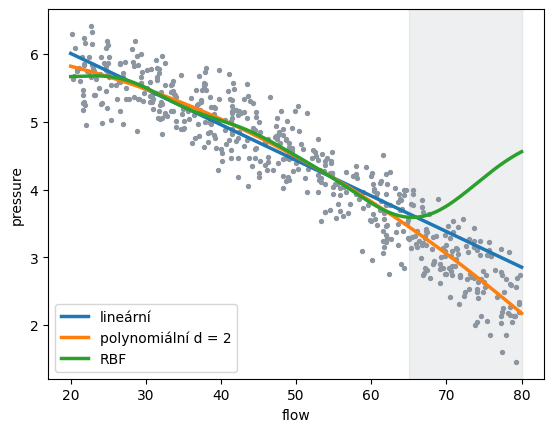

,MAE učební rozsah,MAE nový rozsah
lineární,0.278,0.448
polynomiální d = 2,0.271,0.297
RBF,0.270,1.120


,podpůrné vektory,MAE učební rozsah,MAE nový rozsah
0.05,370.0,0.271,0.298
0.20,230.0,0.271,0.297
0.50,56.0,0.272,0.310


In [13]:
normal = raw.loc[X_dev.index][y_dev == 0]
known = normal["flow"] < 65
X_known, y_known = normal.loc[known, ["flow"]], normal.loc[known, "pressure"]
X_new, y_new = normal.loc[~known, ["flow"]], normal.loc[~known, "pressure"]
regressors = {"lineární": SVR(kernel="linear", C=10, epsilon=0.2),
              "polynomiální d = 2": SVR(kernel="poly", degree=2, coef0=1, C=10, epsilon=0.2),
              "RBF": SVR(kernel="rbf", gamma=1, C=10, epsilon=0.2)}
grid_flow = pd.DataFrame({"flow": np.linspace(20, 80, 200)})
rows = {}
plt.scatter(normal["flow"], normal["pressure"], s=8, color="#8C96A0")
plt.axvspan(65, 80, color="#8C96A0", alpha=0.15)
for name, reg in regressors.items():
    model = Pipeline([("scale", StandardScaler()), ("model", reg)]).fit(X_known, y_known)
    rows[name] = {"MAE učební rozsah": mean_absolute_error(y_known, model.predict(X_known)),
                  "MAE nový rozsah": mean_absolute_error(y_new, model.predict(X_new))}
    plt.plot(grid_flow["flow"], model.predict(grid_flow), lw=2.5, label=name)
plt.xlabel("flow"); plt.ylabel("pressure"); plt.legend(); plt.show()
svr_results = pd.DataFrame(rows).T
display(svr_results.round(3))

rows = {}
for eps in (0.05, 0.2, 0.5):
    model = Pipeline([("scale", StandardScaler()), ("model", SVR(kernel="poly", degree=2, coef0=1, C=10, epsilon=eps))]).fit(X_known, y_known)
    rows[eps] = {"podpůrné vektory": len(model[-1].support_), "MAE učební rozsah": mean_absolute_error(y_known, model.predict(X_known)),
                 "MAE nový rozsah": mean_absolute_error(y_new, model.predict(X_new))}
eps_results = pd.DataFrame(rows).T
display(eps_results.round(3))

**Poznámky k řešení (krok 9).** V učebním rozsahu leží 410 záznamů v pořádku, v novém rozsahu 137. V učebním rozsahu mají všechny tři
modely MAE asi 0,27–0,28 bar. V novém rozsahu drží polynomiální jádro **0,30**, lineární stoupne na 0,45
(charakteristika je parabola, ne přímka) a RBF jádro na **1,12**: mimo data se jeho předpověď vrací ke konstantě,
přesně jako na snímku přednášky. ε = 0,05; 0,2 a 0,5 dá 370, 230 a 56 podpůrných vektorů při téměř stejném MAE (0,30–0,31 v novém rozsahu):
řešení nesou jen body vně trubice a šum 0,45 bar je mnohem větší než kterákoli z trubic.

## Shrnutí

* Třída, která obklopuje tu druhou (odchylka na kteroukoli stranu), potřebuje jádro; lineární model není lepší než náhoda.
* C a γ se ladí společně; nejlepší hodnota na kraji mřížky znamená mřížku rozšířit.
* Práh na skóre SVM se volí podle ceny chyb na vývojových datech, teprve potom se jednou otevře test.
* Jednotřídní SVM funguje bez označených poruch, za cenu slabšího výsledku.
* RBF jádro neextrapoluje; model se správným tvarem (zde parabola) ano.